# Hai biểu đồ giá và điểm review — phần việc của Đô

**Mục tiêu:** mô tả phân bố giá và quan hệ giá–điểm trên dữ liệu sạch.
Đây là **khám phá sơ bộ trên toàn mẫu có giá**. Split seed 42 đã chốt ngày 21/10/2026; hình này chưa chạy riêng trên train.
Mỗi dòng được đếm là một bản ghi review, không mặc định là một chai duy nhất.

Hai hình dùng chung hàm vẽ với notebook tổng hợp. Phần EDA gốc do Đô thực hiện;
phần hoàn thiện cách trình bày và tích hợp do Khánh thực hiện.

## 1. Nạp dữ liệu và chọn mẫu

Đọc wine_cleaned_final.csv một lần. Giữ dữ liệu đầy đủ trong df_all,
chỉ chọn các bản ghi có giá quan sát vào df_price. Không tự điền giá thiếu,
không chạy lại cleaning và không loại giá cao.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "w5_progress_parts":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent
elif PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "wine_cleaned_final.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError("Chưa có dữ liệu sạch. Mở notebook từ project root hoặc thư mục notebook.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.create_eda_plots import plot_price_distribution, plot_price_points

# Chỉ đọc CSV một lần. Không chạy cleaning và không đọc các file split.
df_all = pd.read_csv(DATA_PATH)
required_columns = {
    "price", "points", "log_price", "title", "country", "province",
    "variety", "vintage_year", "price_was_missing",
}
missing_columns = required_columns - set(df_all.columns)
if missing_columns:
    raise ValueError(f"Dữ liệu sạch thiếu cột: {sorted(missing_columns)}")
if df_all.empty:
    raise ValueError("Dữ liệu sạch không có bản ghi.")
if not df_all["price"].isna().equals(df_all["price_was_missing"]):
    raise ValueError("Cờ price_was_missing không khớp trạng thái thiếu giá.")

# df_all luôn là toàn bộ dữ liệu sạch; df_price là bản sao có giá quan sát.
df_price = df_all.loc[df_all["price"].notna()].copy()
if df_price.empty:
    raise ValueError("Không có bản ghi có giá để phân tích.")
for column in ["price", "points"]:
    df_price[column] = pd.to_numeric(df_price[column], errors="raise")
if not (np.isfinite(df_price["price"]) & df_price["price"].gt(0)).all():
    raise ValueError("Giá quan sát phải dương và hữu hạn.")
if not (np.isfinite(df_price["points"]) & df_price["points"].between(80, 100)).all():
    raise ValueError("Điểm review phải đầy đủ, hữu hạn và trong khoảng 80–100.")
if not np.allclose(df_price["log_price"], np.log1p(df_price["price"])):
    raise ValueError("log_price không khớp log1p(price).")

def format_number(value, decimals=0):
    return f"{value:,.{decimals}f}".translate(str.maketrans({",": ".", ".": ","}))

def format_price(value):
    return format_number(value, 2).rstrip("0").rstrip(",")

n_total = len(df_all)
n_with_price = len(df_price)
n_missing_price = int(df_all["price"].isna().sum())
assert n_with_price + n_missing_price == n_total
print(f"Dữ liệu sạch: {format_number(n_total)} bản ghi, {len(df_all.columns)} cột.")
print(f"Mẫu có giá: {format_number(n_with_price)}; thiếu giá: {format_number(n_missing_price)}.")
print("Trạng thái: EDA sơ bộ toàn mẫu có giá; split seed 42 đã chốt; chưa có kiểm định/mô hình.")

Dữ liệu sạch: 119.988 bản ghi, 19 cột.
Mẫu có giá: 111.593; thiếu giá: 8.395.
Trạng thái: EDA sơ bộ toàn mẫu có giá; split seed 42 đã chốt; chưa có kiểm định/mô hình.


## 2. Phân bố giá


Histogram biểu diễn **số bản ghi review**; đường KDE dùng trục mật độ riêng bên phải.
Các vạch dọc đánh dấu giá trung vị và trung bình trên toàn bộ mẫu có giá.

Khung hiển thị 0–300 USD giúp nhìn rõ phần tập trung nhiều dữ liệu. Các bản ghi
giá cao hơn vẫn nằm trong dữ liệu và các thống kê. Chú thích dưới hình ghi số bản ghi
nằm ngoài khung và giá cao nhất; không xóa outlier để làm hình dễ nhìn.

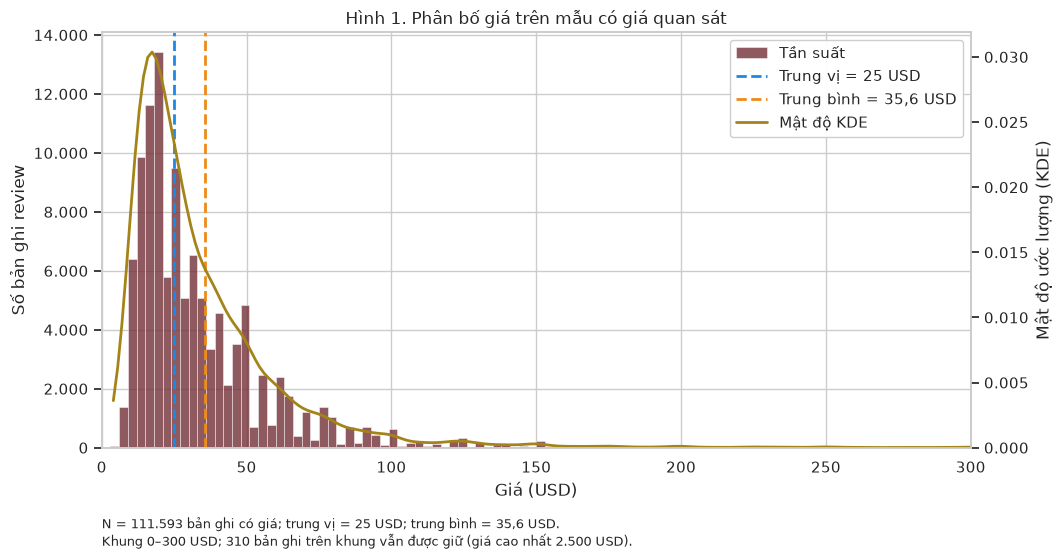

In [2]:
fig_price = plot_price_distribution(df_price)
display(fig_price)
plt.close(fig_price)

### Nhận xét từ toàn mẫu

Các số dưới đây được tính lại mỗi lần chạy.

In [3]:
prices = df_price["price"]
n_above_300 = int(prices.gt(300).sum())
print(
    f"1. Giá trung vị là {format_price(prices.median())} USD, "
    f"trung bình là {format_number(prices.mean(), 1)} USD; phân bố lệch phải."
)
print(
    f"2. Có {format_number(n_above_300)} bản ghi giá trên 300 USD "
    f"({format_number(n_above_300 / len(df_price) * 100, 2)}% mẫu có giá). "
    f"Giá cao nhất {format_price(prices.max())} USD vẫn được giữ."
)
print(
    "3. Nhóm dự kiến dùng log1p(price) cho cấu hình chỉ giá. "
    "Đây là lựa chọn biểu diễn đặc trưng; chưa phải kết quả kiểm tra mô hình."
)

1. Giá trung vị là 25 USD, trung bình là 35,6 USD; phân bố lệch phải.
2. Có 310 bản ghi giá trên 300 USD (0,28% mẫu có giá). Giá cao nhất 2.500 USD vẫn được giữ.
3. Nhóm dự kiến dùng log1p(price) cho cấu hình chỉ giá. Đây là lựa chọn biểu diễn đặc trưng; chưa phải kết quả kiểm tra mô hình.


## 3. Quan hệ giá–điểm


Scatter lấy tối đa **15.000 bản ghi**, với seed cố định 42, từ toàn bộ mẫu có giá.
Chú thích phân biệt số bản ghi toàn mẫu, số được lấy mẫu và số điểm trong khung 0–300 USD.
Seed này chỉ phục vụ vẽ hình. Không vẽ đường hồi quy hoặc dùng các file split.

Màu thể hiện điểm review, độ trong suốt giúp quan sát các điểm chồng lên nhau.
Các nhận xét bên dưới được đối chiếu thêm bằng số đếm từ toàn mẫu, không suy ra
quy luật tuyệt đối từ phần scatter được lấy mẫu.

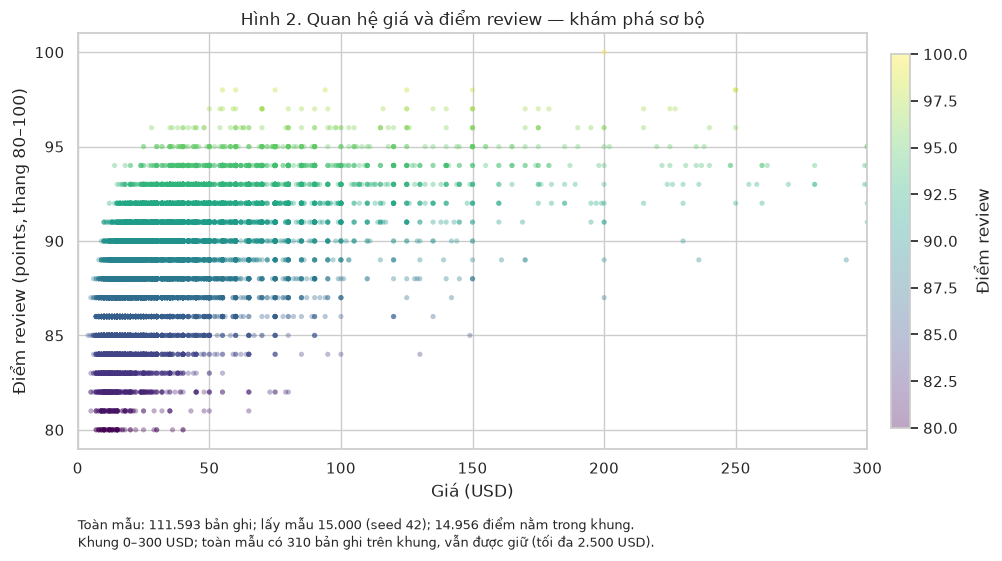

In [4]:
# Seed 42 chỉ dùng lấy mẫu để vẽ, không xác lập train/validation/test.
fig_points = plot_price_points(df_price, max_points=15_000, random_state=42)
display(fig_points)
plt.close(fig_points)

### Nhận xét và câu hỏi tiếp theo

In [5]:
at_25 = df_price.loc[df_price["price"].eq(25), "points"]
high_price_low_points = int(
    (df_price["price"].gt(100) & df_price["points"].lt(85)).sum()
)
print(
    f"1. Ở mức giá 25 USD có {format_number(len(at_25))} bản ghi; "
    f"điểm review từ {format_number(at_25.min())} đến {format_number(at_25.max())}. "
    "Cùng mức giá vẫn có các mức điểm khác nhau."
)
print(
    f"2. Toàn mẫu vẫn có {format_number(high_price_low_points)} bản ghi "
    "giá trên 100 USD nhưng điểm dưới 85. Xu hướng chung có ngoại lệ."
)
print(
    "3. Nhóm sẽ kiểm tra xem metadata có giảm sai số dự đoán ngoài thông tin giá hay không. "
    "Hai biểu đồ mô tả này chưa chứng minh lợi ích dự đoán bổ sung hoặc quan hệ nhân quả."
)

1. Ở mức giá 25 USD có 5.320 bản ghi; điểm review từ 80 đến 95. Cùng mức giá vẫn có các mức điểm khác nhau.
2. Toàn mẫu vẫn có 16 bản ghi giá trên 100 USD nhưng điểm dưới 85. Xu hướng chung có ngoại lệ.
3. Nhóm sẽ kiểm tra xem metadata có giảm sai số dự đoán ngoài thông tin giá hay không. Hai biểu đồ mô tả này chưa chứng minh lợi ích dự đoán bổ sung hoặc quan hệ nhân quả.


## 4. Giới hạn và cách dùng

- Mẫu có giá có thể khác nhóm thiếu giá; dữ liệu review không đại diện toàn bộ thị trường.
- Điểm review là đánh giá của người chấm, không phải thước đo chất lượng khách quan.
- Lấy mẫu và giới hạn trục phục vụ hiển thị, không phải thao tác xóa dữ liệu.
- Metadata có giúp giảm sai số hay không vẫn cần thí nghiệm trên split được duyệt.
- Bước tiếp theo là chạy lại EDA trên train theo roadmap.

**Chạy lại:** chọn kernel môi trường dự án, Restart Kernel rồi Run All, sau đó lưu notebook.
Bản notebook chính của Đô nằm tại thư mục phần việc này.